Covid - 19 Dataset Case Study

Let's Start by importing the libraries.

In [1]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

1. Step 1: Data Loading.

In [2]:
# 1.1.Upload csv files
Confirmed = pd.read_csv('covid_19_confirmed_v1.csv')
deaths = pd.read_csv('covid_19_deaths_v1.csv')
recovered = pd.read_csv('covid_19_recovered_v1.csv')

In [3]:
Confirmed.head()

,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,5/20/21,5/21/21,5/22/21,5/23/21,5/24/21,5/25/21,5/26/21,5/27/21,5/28/21,5/29/21
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,64575,65080,65486,65728,66275,66903,67743,68366,69130,70111
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,132118,132153,132176,132209,132215,132229,132244,132264,132285,132297
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,126156,126434,126651,126860,127107,127361,127646,127926,128198,128456
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,13569,13569,13569,13569,13569,13664,13671,13682,13693,13693
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,31661,31909,32149,32441,32623,32933,33338,33607,33944,34180


2. Step 2: Data Exploration.

In [4]:
#1.2 Checking Dataset Structure
print("Confirmed:", Confirmed.shape)
print("Deaths:", deaths.shape)
print("Recovered:", recovered.shape)

Confirmed: (276, 498)
Deaths: (277, 498)
Recovered: (262, 498)


In [5]:
#1.2.1 checking column names
Confirmed.columns
deaths.columns
recovered.columns

Index(['Column1', 'Column2', 'Column3', 'Column4', 'Column5', 'Column6',
       'Column7', 'Column8', 'Column9', 'Column10',
       ...
       'Column489', 'Column490', 'Column491', 'Column492', 'Column493',
       'Column494', 'Column495', 'Column496', 'Column497', 'Column498'],
      dtype='object', length=498)

In [6]:
#1.2.2 checking datatypes
Confirmed.dtypes
deaths.dtypes
recovered.dtypes

,0
Column1,object
Column2,object
Column3,object
Column4,object
Column5,object
...,...
Column494,object
Column495,object
Column496,object
Column497,object


In [7]:
#1.2.3 check for missing values
Confirmed.isnull().sum().head(10)

,0
Province/State,190
Country/Region,0
Lat,2
Long,2
1/22/20,0
1/23/20,0
1/24/20,0
1/25/20,0
1/26/20,0
1/27/20,0


In [8]:
#1.2.4 Check missing values in all datasets.
Confirmed.isnull().sum().sum()
deaths.isnull().sum().sum()
recovered.isnull().sum().sum()

np.int64(194)

In [9]:
#let's check statistics
Confirmed.describe()
deaths.describe()
recovered.describe()

,Column1,Column2,Column3,Column4,Column5,Column6,Column7,Column8,Column9,Column10,...,Column489,Column490,Column491,Column492,Column493,Column494,Column495,Column496,Column497,Column498
count,71,262,261,261,262,262,262,262,262,262,...,262,262,262,262,262,262,262,262,262,262
unique,71,194,260,260,4,4,6,6,6,8,...,251,249,251,250,249,252,252,252,252,251
top,Province/State,China,0.0,0.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
freq,1,34,2,2,259,258,255,254,253,252,...,8,9,8,8,8,8,8,8,8,8


1.2.5 Explore a few records

In [10]:
print("Confirmed Cases")
print(Confirmed.head())

print("\nDeaths Cases")
print(deaths.head())

print("\nRecovered Cases")
print(recovered.head())

Confirmed Cases
  Province/State Country/Region       Lat       Long  1/22/20  1/23/20  \
0            NaN    Afghanistan  33.93911  67.709953        0        0   
1            NaN        Albania  41.15330  20.168300        0        0   
2            NaN        Algeria  28.03390   1.659600        0        0   
3            NaN        Andorra  42.50630   1.521800        0        0   
4            NaN         Angola -11.20270  17.873900        0        0   

   1/24/20  1/25/20  1/26/20  1/27/20  ...  5/20/21  5/21/21  5/22/21  \
0        0        0        0        0  ...    64575    65080    65486   
1        0        0        0        0  ...   132118   132153   132176   
2        0        0        0        0  ...   126156   126434   126651   
3        0        0        0        0  ...    13569    13569    13569   
4        0        0        0        0  ...    31661    31909    32149   

   5/23/21  5/24/21  5/25/21  5/26/21  5/27/21  5/28/21  5/29/21  
0    65728    66275    66903    6

In [11]:
print("Missing Values in confirmed:")
print(Confirmed.isnull().sum())

print("\nMissing Values in deaths:")
print(deaths.isnull().sum())

print("\nMissing Values in recovered:")
print(recovered.isnull().sum())

Missing Values in confirmed:
Province/State    190
Country/Region      0
Lat                 2
Long                2
1/22/20             0
                 ... 
5/25/21             0
5/26/21             0
5/27/21             0
5/28/21             0
5/29/21             0
Length: 498, dtype: int64

Missing Values in deaths:
Column1      190
Column2        0
Column3        2
Column4        2
Column5        0
            ... 
Column494      0
Column495      0
Column496      0
Column497      0
Column498      0
Length: 498, dtype: int64

Missing Values in recovered:
Column1      191
Column2        0
Column3        1
Column4        1
Column5        0
            ... 
Column494      0
Column495      0
Column496      0
Column497      0
Column498      0
Length: 498, dtype: int64


filling in the null values.

1.2.6 Identified top 3 countries by total cases

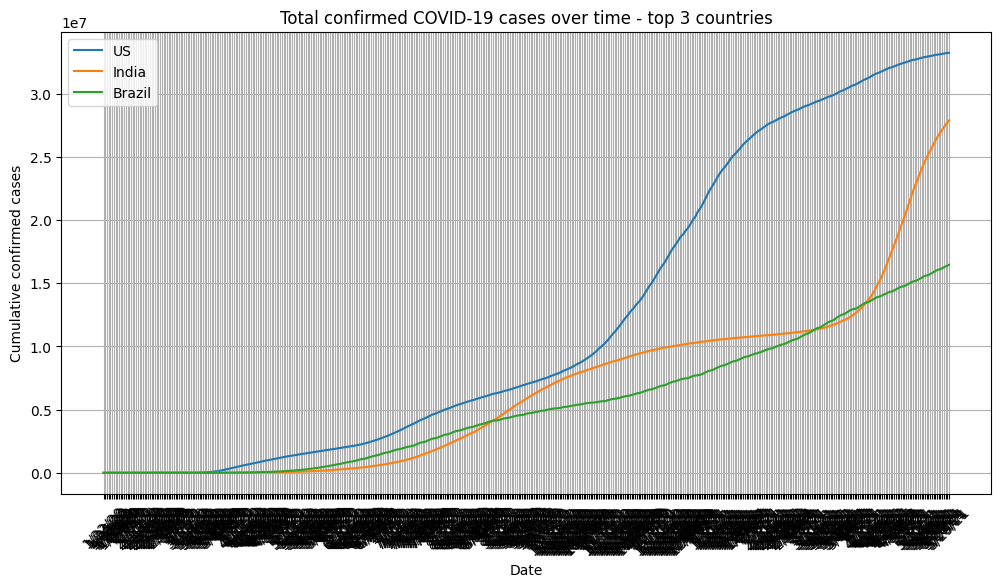

In [12]:
#Total cases over time - Top 3 countries

country_groupby = Confirmed.groupby('Country/Region').sum(numeric_only=True)

top3_countries = country_groupby.iloc[:, -1].sort_values(ascending=False).head(3).index

plt.figure(figsize=(12, 6))
for country in top3_countries:
  country_data = Confirmed[Confirmed['Country/Region'] == country].iloc[:, 4:].sum()
  plt.plot(country_data.index, country_data.values, label=country)
plt.title('Total confirmed COVID-19 cases over time - top 3 countries')
plt.xlabel('Date')
plt.ylabel('Cumulative confirmed cases')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

1.2.7 Confirmed Cases in over time in China

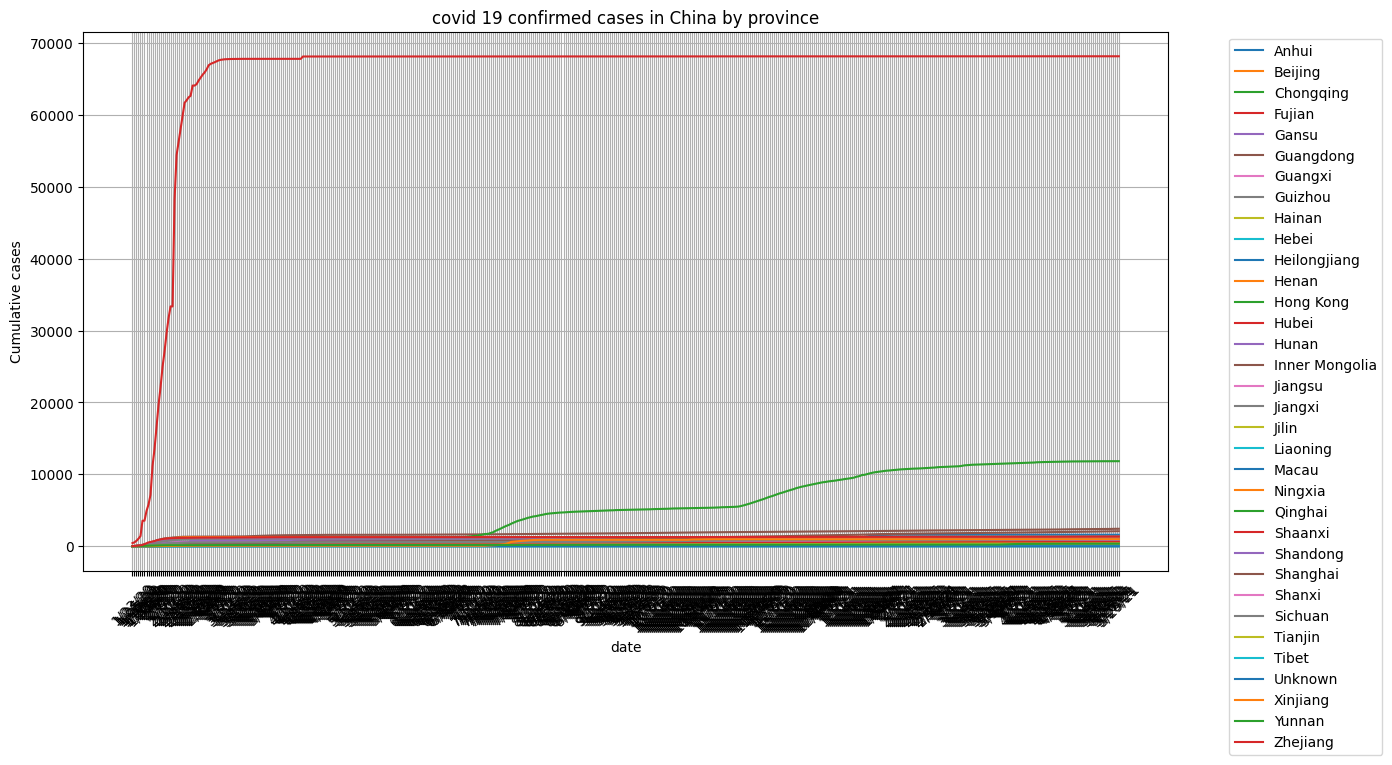

In [14]:
china_data = Confirmed[Confirmed['Country/Region'] == 'China']
china_province_data = china_data.set_index('Province/State').iloc[:, 4:].T

plt.figure(figsize=(14, 7))
for province in china_province_data.columns:
    plt.plot(china_province_data.index, china_province_data[province], label=province)

plt.title("covid 19 confirmed cases in China by province")
plt.xlabel("date")
plt.ylabel("Cumulative cases")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

In [15]:
meta_cols = ["Province/State", "Country/Region", "Lat", "Long"]
date_cols = [c for c in Confirmed.columns if c not in meta_cols]

In [17]:
confirmed_by_country = (
    Confirmed
    .drop(columns=["Lat", "Long"], errors="ignore")
    .groupby("Country/Region", as_index=True)[date_cols]
    .sum()
)

In [18]:
daily_by_country = confirmed_by_country.diff(axis=1)
daily_by_country.iloc[:, 0] = 0
daily_by_country = daily_by_country.clip(lower=0)

Moving Averages by Day 7

In [19]:
daily7_by_country = daily_by_country.rolling(window=7, axis=1, min_periods=1).mean()

/tmp/ipython-input-3200920123.py:1: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  daily7_by_country = daily_by_country.rolling(window=7, axis=1, min_periods=1).mean()


Peak Surges for Days in Selected Countries.

In [20]:
focus_countries = ["Germany", "France", "Italy", "India"]

peak_report = {}

for country in focus_countries:
    series = daily_by_country.loc[country]
    peak_value = int(series.max())
    peak_date = series.idxmax()
    peak_report[country] = {"peak_daily_new": peak_value, "peak_date": peak_date}

print("Peak surge report (daily new cases):")
for k, v in peak_report.items():
    print(f" - {k}: {v['peak_daily_new']} on {v['peak_date']}")

Peak surge report (daily new cases):
 - Germany: 49044 on 12/30/20
 - France: 117900 on 4/11/21
 - Italy: 40902 on 11/13/20
 - India: 414188 on 5/6/21
